## 🎲 Monte Carlo Simulation
###### This model applies Monte Carlo methods and stochastic process simulation to estimate probabilistic future market behavior through large-scale random sampling. Based on statistical physics, quantitative finance, and probability theory, the framework generates thousands of possible price paths using stochastic returns, volatility dynamics, and random shocks to model uncertainty, risk distribution, and future asset scenarios for portfolio analysis and quantitative forecasting.

In [1]:
!pip install pandas numpy yfinance matplotlib scipy seaborn
from IPython.display import clear_output
clear_output()
import pandas as pd, numpy as np, yfinance as yf, matplotlib.pyplot as plt
import scipy.stats as stats, seaborn as sns
from datetime import datetime

plt.style.use('seaborn-v0_8-darkgrid')
RNG = np.random.default_rng(seed=42)  # reproducibility

In [2]:
# Set Ticker and date
ticker = 'TOTS3.SA'
today_str = datetime.now().strftime('%Y-%m-%d')

In [3]:
# Price Data
stock = yf.download(ticker, start='2018-01-01', end=today_str, auto_adjust=False)

if isinstance(stock.columns, pd.MultiIndex):
    stock.columns = stock.columns.get_level_values(0)

# Use LOG returns for GBM consistency
stock['LogReturn'] = np.log(stock['Close'] / stock['Close'].shift(1))
stock.dropna(inplace=True)
stock.sort_index(ascending=True, inplace=True)
stock.tail()

[*********************100%***********************]  1 of 1 completed


Price,Adj Close,Close,High,Low,Open,Volume,LogReturn
Date,,,,,,,
2026-06-09,30.601748,30.790001,32.709999,30.790001,32.599998,7149800,-0.049733
2026-06-10,28.454952,28.629999,30.889999,28.440001,30.790001,9233000,-0.072735
2026-06-11,29.856333,30.040001,30.680000,28.010000,28.450001,10870100,0.048075
2026-06-12,29.617798,29.799999,30.320000,29.330000,29.500000,5094400,-0.008021
2026-06-15,29.260000,29.440001,30.879999,29.410000,30.500000,5062700,-0.012154


Daily log-return mean : 0.0514%
Daily log-return vol  : 2.4498%
Annualized drift      : 12.96%
Annualized volatility : 38.89%
68% band (1 sigma 1d) : +/- 2.45%
95% band (2 sigma 1d) : +/- 4.90%


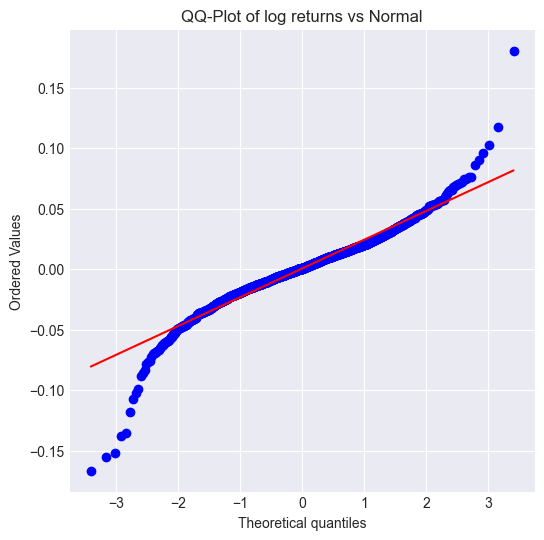

In [4]:
price = float(stock['Close'].iloc[-1])         # Starting point S0
mu_d  = float(stock['LogReturn'].mean())       # Daily log-return mean
sig_d = float(stock['LogReturn'].std())        # Daily log-return std

# Annualized for reporting
mu_ann  = mu_d * 252
sig_ann = sig_d * np.sqrt(252)

print(f'Daily log-return mean : {mu_d:.4%}')
print(f'Daily log-return vol  : {sig_d:.4%}')
print(f'Annualized drift      : {mu_ann:.2%}')
print(f'Annualized volatility : {sig_ann:.2%}')
print(f'68% band (1 sigma 1d) : +/- {sig_d*100:.2f}%')
print(f'95% band (2 sigma 1d) : +/- {sig_d*200:.2f}%')

# Sanity check: log returns should be roughly normal -> QQ plot
fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(stock['LogReturn'].values, dist='norm', plot=ax)
ax.set_title('QQ-Plot of log returns vs Normal')
plt.show()

![GBM](./images/Geometric%20Brownian%20Motion%20-%20GBM.png)

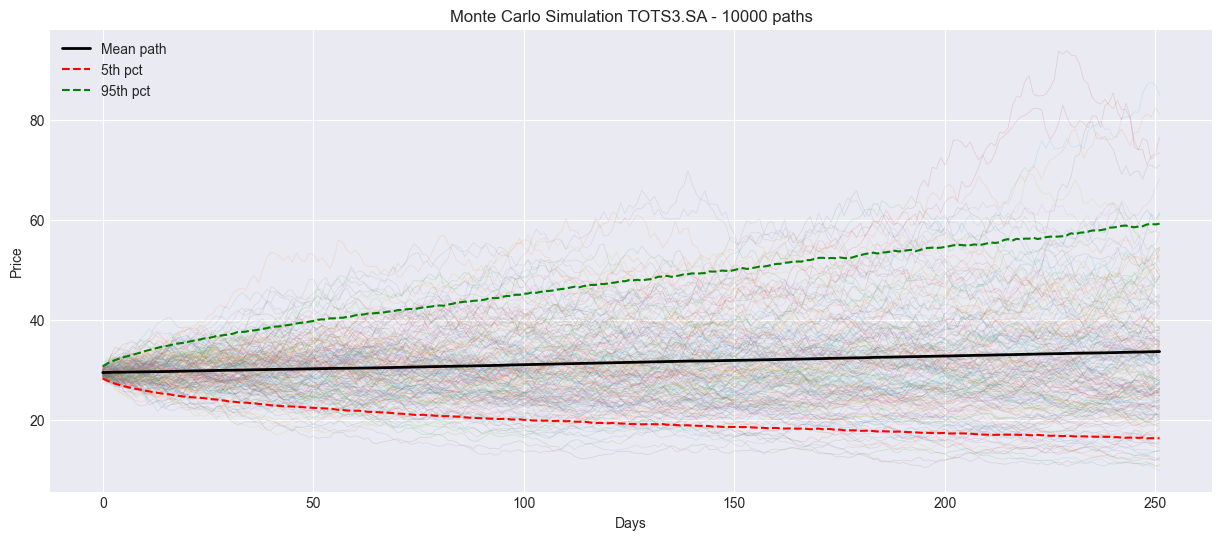

In [5]:
days = 252           # 1-year horizon
sim  = 10000         # Monte Carlo paths
dt   = 1             # daily step (mu_d/sig_d already in daily units)

# Vectorized GBM: log S_t+1 = log S_t + (mu - 0.5 sig^2) dt + sig*sqrt(dt)*Z
Z = RNG.standard_normal(size=(days, sim))
increments = (mu_d - 0.5 * sig_d**2) * dt + sig_d * np.sqrt(dt) * Z
log_paths = np.log(price) + np.cumsum(increments, axis=0)
paths = np.exp(log_paths)

mean_path = paths.mean(axis=1)
p05_path  = np.percentile(paths,  5, axis=1)
p95_path  = np.percentile(paths, 95, axis=1)

fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(paths[:, :200], alpha=0.15, lw=0.6)  # show only 200 paths for clarity
ax.plot(mean_path, color='black', lw=2, label='Mean path')
ax.plot(p05_path,  color='red',   lw=1.5, ls='--', label='5th pct')
ax.plot(p95_path,  color='green', lw=1.5, ls='--', label='95th pct')
ax.set_xlabel('Days')
ax.set_ylabel('Price')
ax.set_title(f'Monte Carlo Simulation {ticker} - {sim} paths')
ax.legend()
plt.show()

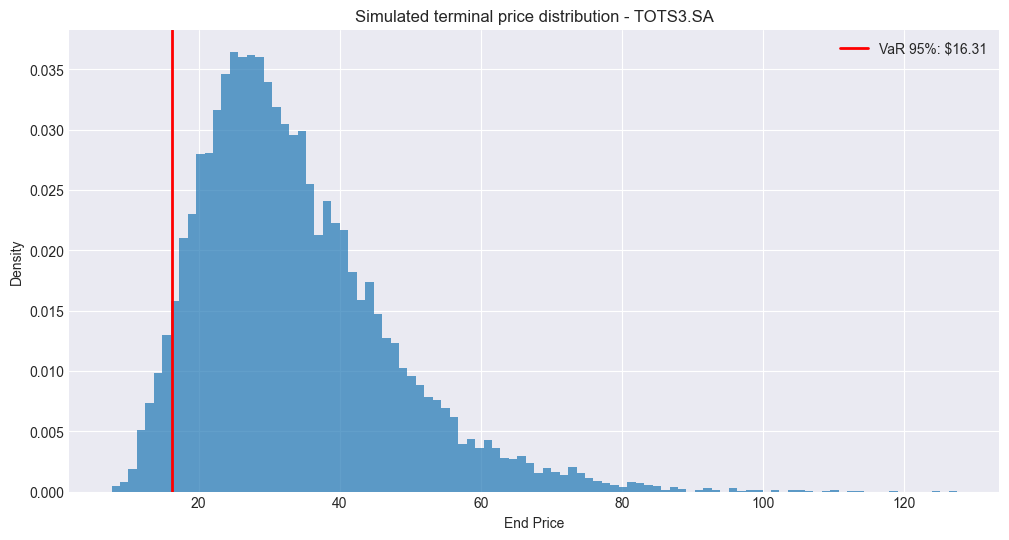

Starting price        : $29.44
Mean terminal price   : $33.64
VaR 95% (price level) : $16.31  -> 5% chance of ending BELOW this
VaR 95% (return)      : -44.59%
ES  95% (CVaR return) : -52.43%   <- avg loss in the worst 5%


In [6]:
end_prices = paths[-1, :]
pnl_pct    = (end_prices / price - 1.0) * 100  # % return at horizon

var_95_price = np.percentile(end_prices, 5)
var_95_pct   = np.percentile(pnl_pct, 5)
es_95_pct    = pnl_pct[pnl_pct <= var_95_pct].mean()   # Expected Shortfall

plt.figure(figsize=(12, 6))
plt.hist(end_prices, bins=100, alpha=0.7, density=True)
plt.axvline(var_95_price, color='r', ls='-', lw=2, label=f'VaR 95%: ${var_95_price:.2f}')
plt.title(f'Simulated terminal price distribution - {ticker}')
plt.xlabel('End Price')
plt.ylabel('Density')
plt.legend()
plt.show()

print(f'Starting price        : ${price:.2f}')
print(f'Mean terminal price   : ${end_prices.mean():.2f}')
print(f'VaR 95% (price level) : ${var_95_price:.2f}  -> 5% chance of ending BELOW this')
print(f'VaR 95% (return)      : {var_95_pct:.2f}%')
print(f'ES  95% (CVaR return) : {es_95_pct:.2f}%   <- avg loss in the worst 5%')

In [7]:
range_min = min(end_prices)
range_max = max(end_prices)
num_bins = 25

bins = np.linspace(range_min, range_max, num_bins)
hist, _ = np.histogram(end_prices, bins=bins)
percentages = (hist / len(end_prices)) * 100

print("Prob Distribution Table\n")

for i in range(len(bins)-1):
    if percentages[i] > 5:   # since percentages are already in %
        print(f"Price Range ${bins[i]:.2f} - ${bins[i+1]:.2f}: {percentages[i]:.2f}%")

Prob Distribution Table

Price Range $12.67 - $17.66: 5.98%
Price Range $17.66 - $22.65: 13.36%
Price Range $22.65 - $27.65: 17.53%
Price Range $27.65 - $32.64: 16.70%
Price Range $32.64 - $37.63: 13.32%
Price Range $37.63 - $42.62: 10.62%
Price Range $42.62 - $47.61: 7.58%
